## 1. Import


In [1]:
import sys
import json
import hashlib
import tempfile
import time
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import cv2
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from skimage.feature import hog, local_binary_pattern
from tqdm.auto import tqdm

LIBRARY_VERSIONS = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "opencv": cv2.__version__,
    "scikit-image": skimage.__version__,
    "h5py": h5py.__version__,
    "matplotlib": version("matplotlib"),
    "tqdm": version("tqdm"),
}
cv2.setNumThreads(1)
print(pd.Series(LIBRARY_VERSIONS, name="version").to_string())


python          3.13.18
numpy             2.1.3
pandas            2.3.3
opencv           4.14.0
scikit-image     0.25.2
h5py             3.14.0
matplotlib       3.10.0
tqdm             4.67.3


## 2. Config


In [2]:
DATA_ROOT = Path("/kaggle/input/datasets/minhquno/real-vs-sdxl-20k")
OUTPUT_DIR = Path("/kaggle/working/real_vs_sdxl_pixels_plus_features_224")
SEED = 42
IMAGE_SIZE = 224

RESIZE_CONFIG = {
    "size_hw": (IMAGE_SIZE, IMAGE_SIZE),
    "mode": "stretch_full_image",
    "downscale": "INTER_AREA",
    "upscale_or_mixed": "INTER_LINEAR",
    "aspect_ratio_preserved": False,
}
BATCH_SIZE = 128
SPLITS = ("train", "val", "test")
LABEL_DIRS = {0: "0_real", 1: "1_sdxl"}
EXPECTED_COUNTS = {"train": {0: 7000, 1: 7000},
                   "val": {0: 1500, 1: 1500},
                   "test": {0: 1500, 1: 1500}}
STRICT_COUNTS = True

AUGMENTATION = {
    "train_fraction_per_class": 0.5,
    "methods": ("rotate", "brightness", "noise"),
    "method_probabilities": (1 / 3, 1 / 3, 1 / 3),
    "rotation_degrees": (-3.0, 3.0),
    "brightness_factor": (0.95, 1.05),
    "noise_sigma_255": (1.0, 2.0),
    "noise_mean": 0.0,
    "rotation_interpolation": "INTER_LINEAR",
    "rotation_border": "BORDER_REFLECT_101",
}
# 224 / 16 = 14 cells per axis; 13 x 13 blocks x 4 cells x 9 bins = 6,084.
HOG_CONFIG = {
    "orientations": 9, "pixels_per_cell": (16, 16),
    "cells_per_block": (2, 2), "block_norm": "L2-Hys",
    "transform_sqrt": False, "feature_vector": True,
}
# LBP riu2(8,1): Ojala et al., TPAMI 2002, DOI 10.1109/TPAMI.2002.1017623.
LBP_CONFIG = {"P": 8, "R": 1, "method": "uniform", "bins": 10,
              "normalization": "L1"}
# Joint H-S-V histogram: 12 bins per axis, producing 12^3 = 1,728 values.
HSV_CONFIG = {
    "bins_per_channel": 12, "histogram_type": "joint_3D",
    "ranges": [[0, 180], [0, 256], [0, 256]],
    "normalization": "L2", "order": ["H", "S", "V"], "flatten_order": "C",
}
FEATURE_DIMS = {"hog": 6084, "lbp": 10, "hsv12": 1728}
ALL_FEATURE_ORDER = ("hog", "lbp", "hsv12")
ALL_FEATURE_DIM = sum(FEATURE_DIMS.values())
# Flatten RGB in row-major HWC order, preserving pixel values on the 0-255 scale.
PIXEL_DIM = IMAGE_SIZE * IMAGE_SIZE * 3
COMBINED_DIMS = {name: PIXEL_DIM + dimension for name, dimension in FEATURE_DIMS.items()}
COMBINED_DIMS["all"] = PIXEL_DIM + ALL_FEATURE_DIM
PIXEL_VECTOR_CONFIG = {"flatten_order": "C", "channel_layout": "HWC_RGB",
                       "storage_dtype": "uint8", "model_dtype": "float32",
                       "value_range": [0, 255], "normalization": None}
HDF5_CONFIG = {"compression": "gzip", "compression_opts": 4, "shuffle": True}
FEATURE_CONFIGS = {
    "hog": {**HOG_CONFIG, "global_normalization": "L2"},
    "lbp": LBP_CONFIG, "hsv12": HSV_CONFIG,
}

CACHE_DIR = Path(tempfile.mkdtemp(prefix="real_sdxl_features_"))

RUN_CONFIG = {
    "seed": SEED, "resize": RESIZE_CONFIG, "batch_size": BATCH_SIZE,
    "labels": LABEL_DIRS, "augmentation": AUGMENTATION,
    "features": FEATURE_CONFIGS, "pixel_vector": PIXEL_VECTOR_CONFIG,
    "representation": "flattened_RGB_then_one_or_all_handcrafted_features",
    "all_feature_order": ALL_FEATURE_ORDER,
    "hdf5": HDF5_CONFIG, "scaler": None, "pca": None,
    "decoder": "OpenCV BGR-to-RGB, ignore EXIF orientation",
}
CONFIG_JSON = json.dumps(RUN_CONFIG, sort_keys=True)
CONFIG_SHA256 = hashlib.sha256(CONFIG_JSON.encode()).hexdigest()
FEATURE_ARRAYS = {}
FEATURE_TIMES = {}
assert IMAGE_SIZE == 224 and BATCH_SIZE > 0
print(json.dumps({"data_root": str(DATA_ROOT), "output_dir": str(OUTPUT_DIR),
                  "cache_dir": str(CACHE_DIR), **RUN_CONFIG}, indent=2))
print("Handcrafted dimensions:", FEATURE_DIMS)
print("All handcrafted features dimension:", ALL_FEATURE_DIM)
print("Flattened RGB dimension:", PIXEL_DIM)
print("Combined ML input dimensions:", COMBINED_DIMS)
print("Config SHA256:", CONFIG_SHA256)


{
  "data_root": "/kaggle/input/datasets/minhquno/real-vs-sdxl-20k",
  "output_dir": "/kaggle/working/real_vs_sdxl_pixels_plus_features_224",
  "cache_dir": "/tmp/real_sdxl_features_77bgagmx",
  "seed": 42,
  "resize": {
    "size_hw": [
      224,
      224
    ],
    "mode": "stretch_full_image",
    "downscale": "INTER_AREA",
    "upscale_or_mixed": "INTER_LINEAR",
    "aspect_ratio_preserved": false
  },
  "batch_size": 128,
  "labels": {
    "0": "0_real",
    "1": "1_sdxl"
  },
  "augmentation": {
    "train_fraction_per_class": 0.5,
    "methods": [
      "rotate",
      "brightness",
      "noise"
    ],
    "method_probabilities": [
      0.3333333333333333,
      0.3333333333333333,
      0.3333333333333333
    ],
    "rotation_degrees": [
      -3.0,
      3.0
    ],
    "brightness_factor": [
      0.95,
      1.05
    ],
    "noise_sigma_255": [
      1.0,
      2.0
    ],
    "noise_mean": 0.0,
    "rotation_interpolation": "INTER_LINEAR",
    "rotation_border": "BORDER_R

## 3. Load Data — RGB


In [3]:

def read_rgb(path):
    flags = cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION
    bgr = cv2.imread(str(path), flags)
    if bgr is None:
        raise ValueError(f"Cannot decode image: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f"Attach the dataset or update DATA_ROOT: {DATA_ROOT}")

records = []
for split in SPLITS:
    for label, folder in LABEL_DIRS.items():
        class_dir = DATA_ROOT / split / folder
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Missing class directory: {class_dir}")
        paths = sorted(p for p in class_dir.rglob("*")
                       if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"})
        if not paths:
            raise ValueError(f"No JPEG images found in {class_dir}")
        # Stop on count mismatches instead of silently changing the benchmark splits.
        if STRICT_COUNTS and len(paths) != EXPECTED_COUNTS[split][label]:
            raise ValueError(f"{split}/{folder}: found {len(paths)}, "
                             f"expected {EXPECTED_COUNTS[split][label]}")
        for path in paths:
            records.append({"split": split, "label": label,
                            "image_id": path.relative_to(DATA_ROOT).as_posix(),
                            "path": str(path)})

manifest = pd.DataFrame(records)

assert manifest["image_id"].is_unique
split_frames = {s: manifest.loc[manifest["split"].eq(s)].reset_index(drop=True).copy()
                for s in SPLITS}
counts = manifest.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(SPLITS)
counts.columns = ["0_real", "1_sdxl"]
counts["total"] = counts.sum(axis=1)

print("Manifest shape:", manifest.shape)
print(counts.to_string())
for split in SPLITS:
    frame = split_frames[split]
    print(f"{split}: manifest={frame.shape}, labels={frame['label'].to_numpy().shape}")
    for label in LABEL_DIRS:
        row = frame.loc[frame["label"].eq(label)].iloc[0]
        rgb = read_rgb(row["path"])
        print(f"  {LABEL_DIRS[label]} sample: RGB shape={rgb.shape}, dtype={rgb.dtype}")

Manifest shape: (20000, 4)
       0_real  1_sdxl  total
split                       
train    7000    7000  14000
val      1500    1500   3000
test     1500    1500   3000
train: manifest=(14000, 4), labels=(14000,)
  0_real sample: RGB shape=(480, 640, 3), dtype=uint8
  1_sdxl sample: RGB shape=(1024, 1024, 3), dtype=uint8
val: manifest=(3000, 4), labels=(3000,)
  0_real sample: RGB shape=(326, 512, 3), dtype=uint8
  1_sdxl sample: RGB shape=(1024, 1024, 3), dtype=uint8
test: manifest=(3000, 4), labels=(3000,)
  0_real sample: RGB shape=(640, 427, 3), dtype=uint8
  1_sdxl sample: RGB shape=(1024, 1024, 3), dtype=uint8


## 4. Resize — 224 x 224


Resize: train:   0%|          | 0/14000 [00:00<?, ?it/s]

train: resized RGB shape=(14000, 224, 224, 3), dtype=uint8
resize_interpolation  INTER_AREA  INTER_LINEAR
label                                         
0                           6990            10
1                           7000             0
Images with at least one enlarged dimension: 10


Resize: val:   0%|          | 0/3000 [00:00<?, ?it/s]

val: resized RGB shape=(3000, 224, 224, 3), dtype=uint8
resize_interpolation  INTER_AREA  INTER_LINEAR
label                                         
0                           1496             4
1                           1500             0
Images with at least one enlarged dimension: 4


Resize: test:   0%|          | 0/3000 [00:00<?, ?it/s]

test: resized RGB shape=(3000, 224, 224, 3), dtype=uint8
resize_interpolation  INTER_AREA  INTER_LINEAR
label                                         
0                           1494             6
1                           1500             0
Images with at least one enlarged dimension: 6


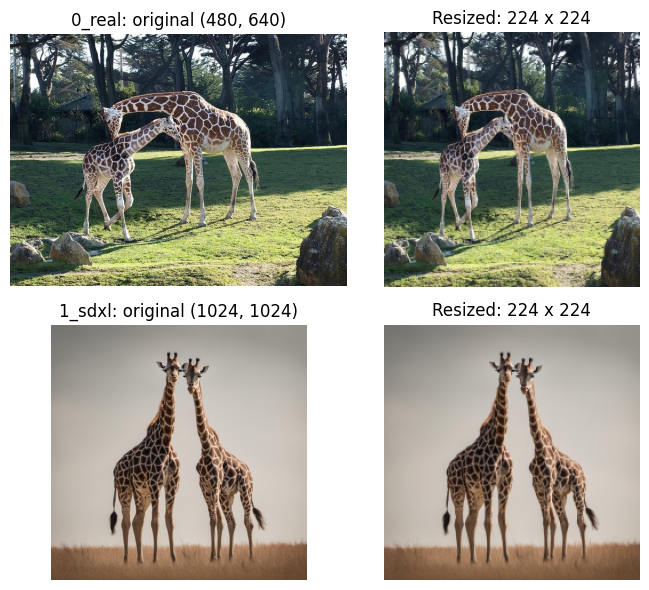

Resize completed


In [4]:
def resize_rgb(rgb):
    height, width = rgb.shape[:2]
    if (height, width) == (IMAGE_SIZE, IMAGE_SIZE):
        return rgb.copy(), "none"
    # Use area interpolation when neither axis needs enlargement.
    # Use bilinear interpolation when either axis is enlarged, including mixed scaling.
    shrinking = height >= IMAGE_SIZE and width >= IMAGE_SIZE
    interpolation = cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR
    method = "INTER_AREA" if shrinking else "INTER_LINEAR"
    resized = cv2.resize(rgb, (IMAGE_SIZE, IMAGE_SIZE), interpolation=interpolation)
    return np.ascontiguousarray(resized), method

# The read-only cache feeds the separate augmentation cell.
RESIZED_FRAMES = {}
RESIZE_CACHE = {}
for split in SPLITS:
    frame = split_frames[split].copy()
    cached = np.lib.format.open_memmap(CACHE_DIR / f"{split}_resized.npy", mode="w+",
        dtype=np.uint8, shape=(len(frame), IMAGE_SIZE, IMAGE_SIZE, 3))
    shapes, methods = [], []
    for index, row in enumerate(tqdm(frame.itertuples(index=False), total=len(frame),
                                     desc=f"Resize: {split}")):
        try:
            rgb = read_rgb(row.path)
            resized, method = resize_rgb(rgb)
        except Exception as exc:
            raise RuntimeError(f"Resize failed for {row.image_id}") from exc
        assert resized.shape == (IMAGE_SIZE, IMAGE_SIZE, 3) and resized.dtype == np.uint8
        cached[index] = resized
        shapes.append(rgb.shape[:2])
        methods.append(method)
    cached.flush()
    del cached
    frame["original_height"] = [shape[0] for shape in shapes]
    frame["original_width"] = [shape[1] for shape in shapes]
    frame["resize_interpolation"] = methods
    RESIZED_FRAMES[split] = frame
    RESIZE_CACHE[split] = np.load(CACHE_DIR / f"{split}_resized.npy", mmap_mode="r")
    enlarged = ((frame["original_height"] < IMAGE_SIZE) | (frame["original_width"] < IMAGE_SIZE))
    print(f"{split}: resized RGB shape={RESIZE_CACHE[split].shape}, dtype=uint8")
    print(pd.crosstab(frame["label"], frame["resize_interpolation"]).to_string())
    print(f"Images with at least one enlarged dimension: {int(enlarged.sum())}")
RESIZED_CONFIG_SHA256 = CONFIG_SHA256

fig, axes = plt.subplots(len(LABEL_DIRS), 2, figsize=(7, 3 * len(LABEL_DIRS)), squeeze=False)
for row_index, (label, folder) in enumerate(LABEL_DIRS.items()):
    sample_index = RESIZED_FRAMES["train"].index[
        RESIZED_FRAMES["train"]["label"].eq(label)][0]
    original = read_rgb(RESIZED_FRAMES["train"].at[sample_index, "path"])
    axes[row_index, 0].imshow(original)
    axes[row_index, 0].set_title(f"{folder}: original {original.shape[:2]}")
    axes[row_index, 1].imshow(RESIZE_CACHE["train"][sample_index])
    axes[row_index, 1].set_title(f"Resized: {IMAGE_SIZE} x {IMAGE_SIZE}")
    for axis in axes[row_index]:
        axis.axis("off")
plt.tight_layout()
plt.show()
print("Resize completed")


## 5. Train Augmentation


Augmentation: train:   0%|          | 0/14000 [00:00<?, ?it/s]

train: prepared RGB shape=(14000, 224, 224, 3), dtype=uint8
augmentation  brightness  noise  none  rotate
label                                        
0                   1163   1138  3500    1199
1                   1177   1170  3500    1153


Augmentation: val:   0%|          | 0/3000 [00:00<?, ?it/s]

val: prepared RGB shape=(3000, 224, 224, 3), dtype=uint8
augmentation  none
label             
0             1500
1             1500


Augmentation: test:   0%|          | 0/3000 [00:00<?, ?it/s]

test: prepared RGB shape=(3000, 224, 224, 3), dtype=uint8
augmentation  none
label             
0             1500
1             1500


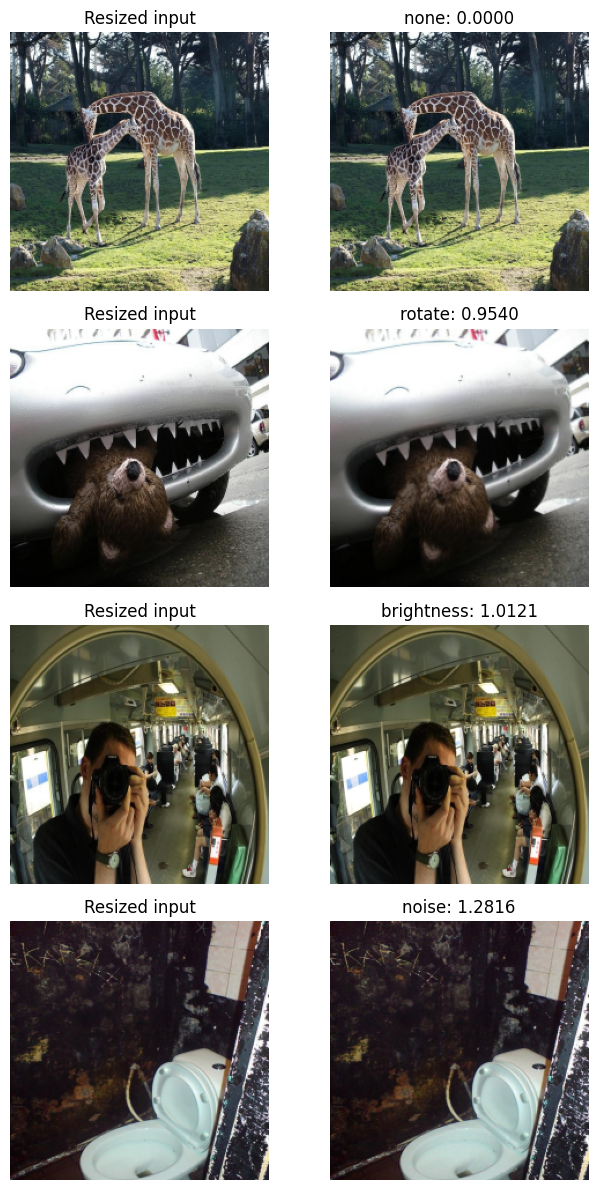

Augmentation completed.


In [5]:
def image_seed(image_id):
    token = f"{SEED}|{image_id}".encode()
    return int.from_bytes(hashlib.sha256(token).digest()[:8], "little")

def apply_augmentation(rgb, method, parameter, seed):
    if method == "none":
        return rgb.copy()
    # Reflect boundary pixels to avoid black corners after a small rotation.
    if method == "rotate":
        center = ((IMAGE_SIZE - 1) / 2, (IMAGE_SIZE - 1) / 2)
        matrix = cv2.getRotationMatrix2D(center, parameter, 1.0)
        return cv2.warpAffine(rgb, matrix, (IMAGE_SIZE, IMAGE_SIZE),
                              flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    # Compute in float32 to avoid uint8 overflow before clipping.
    values = rgb.astype(np.float32)
    if method == "brightness":
        # Share one brightness factor across all RGB channels.
        values *= parameter
    elif method == "noise":
        rng = np.random.default_rng(int(seed))
        # Noise sigma is measured on the 0-255 pixel scale, not on 0-1 values.
        values += rng.normal(0.0, parameter, size=rgb.shape).astype(np.float32)
    else:
        raise ValueError(f"Unknown augmentation: {method}")
    # Round and clip before casting so values cannot wrap around the uint8 range.
    return np.clip(np.rint(values), 0, 255).astype(np.uint8)



if RESIZED_CONFIG_SHA256 != CONFIG_SHA256:
    raise RuntimeError("Configuration changed. Rerun the resize cell.")
PREPARED_FRAMES = {}
RGB_CACHE = {}
preview_pairs = {}
selection_rng = np.random.default_rng(SEED)
for split in SPLITS:
    frame = RESIZED_FRAMES[split].copy()
    frame["augmentation"] = "none"
    frame["aug_parameter"] = 0.0
    frame["aug_seed"] = np.array([image_seed(x) for x in frame["image_id"]], dtype=np.uint64)
    if split == "train":
        for label in LABEL_DIRS:
            candidates = frame.index[frame["label"].eq(label)].to_numpy()
            if len(candidates) % 2:
                raise ValueError("Exact 50/50 augmentation requires even class counts.")
            # Sampling without replacement selects exactly half of this class.
            chosen = selection_rng.choice(candidates, size=len(candidates) // 2, replace=False)
            for index in chosen:
                rng = np.random.default_rng(int(frame.at[index, "aug_seed"]))
                # Choose one method with equal probability, then sample its strength.
                method = str(rng.choice(AUGMENTATION["methods"],
                                        p=AUGMENTATION["method_probabilities"]))
                key = {"rotate": "rotation_degrees", "brightness": "brightness_factor",
                       "noise": "noise_sigma_255"}[method]
                frame.at[index, "augmentation"] = method
                frame.at[index, "aug_parameter"] = float(rng.uniform(*AUGMENTATION[key]))

    cached = np.lib.format.open_memmap(CACHE_DIR / f"{split}_rgb.npy", mode="w+",
        dtype=np.uint8, shape=(len(frame), IMAGE_SIZE, IMAGE_SIZE, 3))
    hashes = []
    for index, row in enumerate(tqdm(frame.itertuples(index=False), total=len(frame),
                                     desc=f"Augmentation: {split}")):
        rgb = RESIZE_CACHE[split][index]
        prepared = apply_augmentation(rgb, row.augmentation, row.aug_parameter, row.aug_seed)
        assert prepared.shape == (IMAGE_SIZE, IMAGE_SIZE, 3) and prepared.dtype == np.uint8
        cached[index] = prepared
        # Record exact prepared-input identity for alignment checks across output files.
        hashes.append(hashlib.sha256(prepared.tobytes()).hexdigest())
        if split == "train" and row.augmentation not in preview_pairs:
            preview_pairs[row.augmentation] = (rgb.copy(), prepared.copy(), row.aug_parameter)
    cached.flush()
    del cached
    frame["prepared_sha256"] = hashes
    PREPARED_FRAMES[split] = frame
    RGB_CACHE[split] = np.load(CACHE_DIR / f"{split}_rgb.npy", mmap_mode="r")
    # Verify the train ratio and ensure validation/test pixels stayed unchanged.
    if split == "train":
        for label in LABEL_DIRS:
            selected = frame.loc[frame["label"].eq(label), "augmentation"].ne("none").sum()
            assert selected == frame["label"].eq(label).sum() // 2
    else:
        assert frame["augmentation"].eq("none").all()
        assert np.array_equal(RGB_CACHE[split], RESIZE_CACHE[split])
    print(f"{split}: prepared RGB shape={RGB_CACHE[split].shape}, dtype=uint8")
    print(pd.crosstab(frame["label"], frame["augmentation"]).to_string())
PREPARED_CONFIG_SHA256 = CONFIG_SHA256

# Preview the frozen transformations used by every extractor.
methods = [m for m in ("none", "rotate", "brightness", "noise") if m in preview_pairs]
fig, axes = plt.subplots(len(methods), 2, figsize=(7, 3 * len(methods)), squeeze=False)
for row_index, method in enumerate(methods):
    before, after, parameter = preview_pairs[method]
    axes[row_index, 0].imshow(before)
    axes[row_index, 0].set_title("Resized input")
    axes[row_index, 1].imshow(after)
    axes[row_index, 1].set_title(f"{method}: {parameter:.4f}")
    for axis in axes[row_index]:
        axis.axis("off")
plt.tight_layout()
plt.show()
print("Augmentation completed.")


## 6. Feature Engineering


### 6.1. HOG


In [6]:
# Reuse the same frozen RGB cache for every feature family.
# Keep feature matrices on disk and compute only one batch at a time.
def extract_feature_set(name, extractor):
    if PREPARED_CONFIG_SHA256 != CONFIG_SHA256:
        raise RuntimeError("Configuration changed. Rerun resize and augmentation before extraction.")
    dimension = FEATURE_DIMS[name]
    result = {}
    started = time.perf_counter()
    for split in SPLITS:
        images = RGB_CACHE[split]
        features = np.lib.format.open_memmap(CACHE_DIR / f"{split}_{name}.npy", mode="w+",
                                            dtype=np.float32, shape=(len(images), dimension))
        for start in tqdm(range(0, len(images), BATCH_SIZE), desc=f"{name.upper()}: {split}"):
            stop = min(start + BATCH_SIZE, len(images))
            batch = np.asarray([extractor(image) for image in images[start:stop]], dtype=np.float32)
            # Reject wrong dimensions and non-finite values before storing the batch.
            if batch.shape != (stop - start, dimension) or not np.isfinite(batch).all():
                raise ValueError(f"Invalid {name} features: split={split}, start={start}")
            features[start:stop] = batch
        features.flush()
        del features
        result[split] = np.load(CACHE_DIR / f"{split}_{name}.npy", mmap_mode="r")
        print(f"{name}/{split}: handcrafted={result[split].shape}, "
              f"combined X=({len(images)}, {COMBINED_DIMS[name]}), "
              f"y={PREPARED_FRAMES[split]['label'].shape}, dtype=float32, finite=True")
    FEATURE_ARRAYS[name] = result
    FEATURE_TIMES[name] = time.perf_counter() - started
    print(f"{name.upper()} completed in {FEATURE_TIMES[name]:.2f} seconds.")


# Normalize the complete descriptor; preserve zero vectors without dividing by zero.
def l2_normalize(vector):
    norm = float(np.linalg.norm(vector))
    if norm > 0:
        vector = vector / norm
    return vector.astype(np.float32)


# L2-Hys acts on each block; the second normalization acts on all 6,084 values.
def extract_hog(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    vector = hog(gray, **HOG_CONFIG).astype(np.float32)
    return l2_normalize(vector)


extract_feature_set("hog", extract_hog)
for split in SPLITS:
    norms = np.linalg.norm(FEATURE_ARRAYS["hog"][split], axis=1)
    assert np.all(np.isclose(norms, 1.0, atol=1e-6) | (norms == 0))
print("HOG validation passed: 6,084 values, block L2-Hys and full-vector L2.")


HOG: train:   0%|          | 0/110 [00:00<?, ?it/s]

hog/train: handcrafted=(14000, 6084), combined X=(14000, 156612), y=(14000,), dtype=float32, finite=True


HOG: val:   0%|          | 0/24 [00:00<?, ?it/s]

hog/val: handcrafted=(3000, 6084), combined X=(3000, 156612), y=(3000,), dtype=float32, finite=True


HOG: test:   0%|          | 0/24 [00:00<?, ?it/s]

hog/test: handcrafted=(3000, 6084), combined X=(3000, 156612), y=(3000,), dtype=float32, finite=True
HOG completed in 211.91 seconds.
HOG validation passed: 6,084 values, block L2-Hys and full-vector L2.


### 6.2. LBP


In [7]:
# Compare local neighbors with the center pixel using rotation-invariant uniform LBP.
# Keep grayscale as uint8 to avoid floating-point threshold artifacts.
def extract_lbp(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    codes = local_binary_pattern(gray, LBP_CONFIG["P"], LBP_CONFIG["R"],
                                 method=LBP_CONFIG["method"])
    # Count all ten codes, including bins absent from this image.
    histogram = np.bincount(codes.astype(np.uint8).ravel(),
                            minlength=LBP_CONFIG["bins"]).astype(np.float32)
    # L1 normalization converts pixel counts to relative frequencies.
    histogram /= histogram.sum()
    return histogram

extract_feature_set("lbp", extract_lbp)
for split in SPLITS:
    assert np.allclose(FEATURE_ARRAYS["lbp"][split].sum(axis=1), 1.0, atol=1e-6)
print("LBP validation passed: every histogram sums to 1.")


LBP: train:   0%|          | 0/110 [00:00<?, ?it/s]

lbp/train: handcrafted=(14000, 10), combined X=(14000, 150538), y=(14000,), dtype=float32, finite=True


LBP: val:   0%|          | 0/24 [00:00<?, ?it/s]

lbp/val: handcrafted=(3000, 10), combined X=(3000, 150538), y=(3000,), dtype=float32, finite=True


LBP: test:   0%|          | 0/24 [00:00<?, ?it/s]

lbp/test: handcrafted=(3000, 10), combined X=(3000, 150538), y=(3000,), dtype=float32, finite=True
LBP completed in 211.75 seconds.
LBP validation passed: every histogram sums to 1.


### 6.3. HSV12 Histogram


In [8]:
# Count joint H-S-V combinations with 12 bins on each axis, then normalize by L2.
def extract_hsv12(rgb):
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    bins = HSV_CONFIG["bins_per_channel"]
    ranges = [bound for channel_range in HSV_CONFIG["ranges"] for bound in channel_range]
    histogram = cv2.calcHist([hsv], [0, 1, 2], None, [bins, bins, bins], ranges)
    vector = histogram.ravel(order="C").astype(np.float32)
    return l2_normalize(vector)


extract_feature_set("hsv12", extract_hsv12)
for split in SPLITS:
    norms = np.linalg.norm(FEATURE_ARRAYS["hsv12"][split], axis=1)
    assert np.allclose(norms, 1.0, atol=1e-6)
print("HSV12 validation passed: joint 12 x 12 x 12 histogram, 1,728 values, L2 norm=1.")


HSV12: train:   0%|          | 0/110 [00:00<?, ?it/s]

hsv12/train: handcrafted=(14000, 1728), combined X=(14000, 152256), y=(14000,), dtype=float32, finite=True


HSV12: val:   0%|          | 0/24 [00:00<?, ?it/s]

hsv12/val: handcrafted=(3000, 1728), combined X=(3000, 152256), y=(3000,), dtype=float32, finite=True


HSV12: test:   0%|          | 0/24 [00:00<?, ?it/s]

hsv12/test: handcrafted=(3000, 1728), combined X=(3000, 152256), y=(3000,), dtype=float32, finite=True
HSV12 completed in 9.70 seconds.
HSV12 validation passed: joint 12 x 12 x 12 histogram, 1,728 values, L2 norm=1.


## 7. Output — Pixels + Feature


In [9]:
# Verify pixel and feature blocks against the same prepared RGB arrays.
def verify_combined_file(path, feature_names):
    dimension = sum(FEATURE_DIMS[feature] for feature in feature_names)
    with h5py.File(path, "r") as handle:
        for split in SPLITS:
            frame = PREPARED_FRAMES[split]
            group = handle[split]
            assert group["X"].shape == (len(frame), PIXEL_DIM + dimension)
            assert group["X"].dtype == np.float32 and group["X"].is_virtual
            assert np.array_equal(group["y"][:], frame["label"].to_numpy())
            assert group["image_ids"].asstr()[:].tolist() == frame["image_id"].tolist()
            assert group["prepared_sha256"].asstr()[:].tolist() == frame["prepared_sha256"].tolist()
            for start in range(0, len(frame), BATCH_SIZE):
                stop = min(start + BATCH_SIZE, len(frame))
                combined = group["X"][start:stop]
                expected_pixels = RGB_CACHE[split][start:stop].reshape(stop - start, PIXEL_DIM)
                assert np.isfinite(combined).all()
                assert np.array_equal(combined[:, :PIXEL_DIM], expected_pixels)
                column = PIXEL_DIM
                for feature in feature_names:
                    next_column = column + FEATURE_DIMS[feature]
                    expected = FEATURE_ARRAYS[feature][split][start:stop]
                    assert np.array_equal(combined[:, column:next_column], expected)
                    column = next_column
            print(f"Verified {path.name}/{split}: X={group['X'].shape}, y={group['y'].shape}")


# Export three independent inputs plus a fourth input containing all three features.
# Every file is self-contained; scaler and PCA are fitted later on train only.
if set(FEATURE_ARRAYS) != set(FEATURE_DIMS):
    raise RuntimeError("Run all three feature cells before exporting.")
if CONFIG_SHA256 != PREPARED_CONFIG_SHA256:
    raise RuntimeError("Configuration changed. Rerun resize and augmentation.")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exported = []
string_dtype = h5py.string_dtype(encoding="utf-8")

for name in ("hog", "lbp", "hsv12", "all"):
    feature_names = list(ALL_FEATURE_ORDER) if name == "all" else [name]
    dimension = sum(FEATURE_DIMS[feature] for feature in feature_names)
    feature_config = FEATURE_CONFIGS if name == "all" else FEATURE_CONFIGS[name]
    destination = OUTPUT_DIR / f"pixels_{name}_features.h5"
    temporary = destination.with_suffix(".h5.partial")

    with h5py.File(temporary, "w", libver="latest") as handle:
        handle.attrs["feature_name"] = name
        handle.attrs["feature_dimension"] = PIXEL_DIM + dimension
        handle.attrs["handcrafted_dimension"] = dimension
        handle.attrs["pixel_dimension"] = PIXEL_DIM
        handle.attrs["feature_order_json"] = json.dumps(feature_names)
        handle.attrs["vector_order"] = "flattened_RGB_then_handcrafted"
        handle.attrs["pixel_value_range"] = (0, 255)
        handle.attrs["pixel_flatten_order"] = "C_HWC_RGB"
        handle.attrs["input_shape_hwc"] = (IMAGE_SIZE, IMAGE_SIZE, 3)
        handle.attrs["created_at_utc"] = datetime.now(timezone.utc).isoformat()
        handle.attrs["config_json"] = CONFIG_JSON
        handle.attrs["config_sha256"] = CONFIG_SHA256
        handle.attrs["library_versions_json"] = json.dumps(LIBRARY_VERSIONS, sort_keys=True)
        handle.attrs["feature_config_json"] = json.dumps(feature_config, sort_keys=True)
        handle.attrs["label_mapping_json"] = json.dumps(LABEL_DIRS)
        handle.attrs["extraction_seconds"] = sum(FEATURE_TIMES[feature] for feature in feature_names)
        handle.attrs["standard_scaler_applied"] = False
        handle.attrs["pca_applied"] = False

        for split in SPLITS:
            frame = PREPARED_FRAMES[split]
            group = handle.create_group(split)
            rows_per_chunk = min(32, len(frame))
            pixels = group.create_dataset(
                "pixel_vectors", shape=(len(frame), PIXEL_DIM), dtype=np.uint8,
                chunks=(rows_per_chunk, min(4096, PIXEL_DIM)), **HDF5_CONFIG,
            )
            handcrafted = group.create_dataset(
                "handcrafted_features", shape=(len(frame), dimension), dtype=np.float32,
                chunks=(rows_per_chunk, min(4096, dimension)), **HDF5_CONFIG,
            )

            # Write RGB once and append each descriptor in the specified column order.
            for start in tqdm(range(0, len(frame), BATCH_SIZE), desc=f"Export pixels + {name}: {split}"):
                stop = min(start + BATCH_SIZE, len(frame))
                pixels[start:stop] = RGB_CACHE[split][start:stop].reshape(stop - start, PIXEL_DIM)
                column = 0
                for feature in feature_names:
                    next_column = column + FEATURE_DIMS[feature]
                    handcrafted[start:stop, column:next_column] = FEATURE_ARRAYS[feature][split][start:stop]
                    column = next_column

            # A virtual X exposes float32 [pixels, features] without duplicating pixel storage.
            # Both sources are inside this file; '.' allows moving or renaming the file.
            layout = h5py.VirtualLayout(shape=(len(frame), PIXEL_DIM + dimension), dtype=np.float32)
            pixel_source = h5py.VirtualSource(".", pixels.name, shape=pixels.shape)
            feature_source = h5py.VirtualSource(".", handcrafted.name, shape=handcrafted.shape)
            layout[:, :PIXEL_DIM] = pixel_source
            layout[:, PIXEL_DIM:] = feature_source
            group.create_virtual_dataset("X", layout, fillvalue=np.nan)
            group.attrs["pixel_columns"] = (0, PIXEL_DIM)
            group.attrs["handcrafted_columns"] = (PIXEL_DIM, PIXEL_DIM + dimension)
            column = PIXEL_DIM
            for feature in feature_names:
                next_column = column + FEATURE_DIMS[feature]
                group.attrs[f"{feature}_columns"] = (column, next_column)
                column = next_column

            # Preserve labels, source IDs, and the shared augmentation plan in all four files.
            group.create_dataset("y", data=frame["label"].to_numpy(dtype=np.uint8))
            for column, key in [
                ("image_id", "image_ids"), ("augmentation", "augmentation"),
                ("prepared_sha256", "prepared_sha256"), ("resize_interpolation", "resize_interpolation"),
            ]:
                group.create_dataset(key, data=frame[column].tolist(), dtype=string_dtype)
            group.create_dataset("aug_parameter", data=frame["aug_parameter"].to_numpy(dtype=np.float64))
            group.create_dataset("aug_seed", data=frame["aug_seed"].to_numpy(dtype=np.uint64))
            group.create_dataset("original_size_hw", data=frame[
                ["original_height", "original_width"]].to_numpy(dtype=np.int32))
            group.attrs["manifest_sha256"] = hashlib.sha256(
                "\n".join(frame["image_id"]).encode()).hexdigest()
            group.attrs["prepared_inputs_sha256"] = hashlib.sha256(
                "\n".join(frame["prepared_sha256"]).encode()).hexdigest()
            group.attrs["augmentation_parameter_units"] = "rotate=degrees; brightness=factor; noise=sigma_255; none=0"

    verify_combined_file(temporary, feature_names)
    temporary.replace(destination)
    with h5py.File(destination, "r") as handle:
        for split in SPLITS:
            sample_parts = [RGB_CACHE[split][0].reshape(-1).astype(np.float32)]
            for feature in feature_names:
                sample_parts.append(FEATURE_ARRAYS[feature][split][0])
            assert np.array_equal(handle[split]["X"][0], np.concatenate(sample_parts))
    exported.append({
        "file": destination.name, "size_MiB": round(destination.stat().st_size / 2**20, 2),
        "pixel_dim": PIXEL_DIM, "feature_dim": dimension,
        "combined_dim": PIXEL_DIM + dimension, "path": str(destination),
    })

print(pd.DataFrame(exported).to_string(index=False))
print("Export completed: four self-contained .h5 files with float32 X and labels y.")
print("Fourth file order: RGB pixels (150528), HOG (6084), LBP (10), HSV12 (1728).")
print("Read train/X and train/y in batches for ML. Fit scaler/PCA on train only.")
print("No scaler, PCA, or classifier is fitted here.")
print("Temporary arrays are outside the output folder:", CACHE_DIR)


Export pixels + hog: train:   0%|          | 0/110 [00:00<?, ?it/s]

Export pixels + hog: val:   0%|          | 0/24 [00:00<?, ?it/s]

Export pixels + hog: test:   0%|          | 0/24 [00:00<?, ?it/s]

Verified pixels_hog_features.h5.partial/train: X=(14000, 156612), y=(14000,)
Verified pixels_hog_features.h5.partial/val: X=(3000, 156612), y=(3000,)
Verified pixels_hog_features.h5.partial/test: X=(3000, 156612), y=(3000,)


Export pixels + lbp: train:   0%|          | 0/110 [00:00<?, ?it/s]

Export pixels + lbp: val:   0%|          | 0/24 [00:00<?, ?it/s]

... (6 outputs left out)

Export pixels + all: train:   0%|          | 0/110 [00:00<?, ?it/s]

Export pixels + all: val:   0%|          | 0/24 [00:00<?, ?it/s]

Export pixels + all: test:   0%|          | 0/24 [00:00<?, ?it/s]

Verified pixels_all_features.h5.partial/train: X=(14000, 158350), y=(14000,)
Verified pixels_all_features.h5.partial/val: X=(3000, 158350), y=(3000,)
Verified pixels_all_features.h5.partial/test: X=(3000, 158350), y=(3000,)
                    file  size_MiB  pixel_dim  feature_dim  combined_dim                                                                           path
  pixels_hog_features.h5   2526.73     150528         6084        156612   /kaggle/working/real_vs_sdxl_pixels_plus_features_224/pixels_hog_features.h5
  pixels_lbp_features.h5   2156.31     150528           10        150538   /kaggle/working/real_vs_sdxl_pixels_plus_features_224/pixels_lbp_features.h5
pixels_hsv12_features.h5   2189.61     150528         1728        152256 /kaggle/working/real_vs_sdxl_pixels_plus_features_224/pixels_hsv12_features.h5
  pixels_all_features.h5   2562.68     150528         7822        158350   /kaggle/working/real_vs_sdxl_pixels_plus_features_224/pixels_all_features.h5
Export completed